Dataset: 2000-01-31 to 2026-06-30
Total observations: 318
2000–2007: Vor der Finanzkrise: Train = 71, Test = 19
2008–2019: Finanzkrise und Niedrigzinsphase: Train = 109, Test = 29
2020–2026: Pandemie und Inflationsphase: Train = 57, Test = 15

Forecast Performance by Economic Period
                                     Period          Model  Train_N  Test_N    MAE   RMSE         R2
             2000–2007: Vor der Finanzkrise        Ridge A       71      19 0.1897 0.2221     0.7401
             2000–2007: Vor der Finanzkrise        Ridge B       71      19 0.1721 0.1943     0.8011
             2000–2007: Vor der Finanzkrise Naive Forecast       71      19 0.2368 0.2810     0.5839
2008–2019: Finanzkrise und Niedrigzinsphase        Ridge A      109      29 1.2047 1.2234 -1257.8305
2008–2019: Finanzkrise und Niedrigzinsphase        Ridge B      109      29 0.7899 0.8034  -541.8108
2008–2019: Finanzkrise und Niedrigzinsphase Naive Forecast      109      29 0.0103 0.0322     0.1300
    2020–

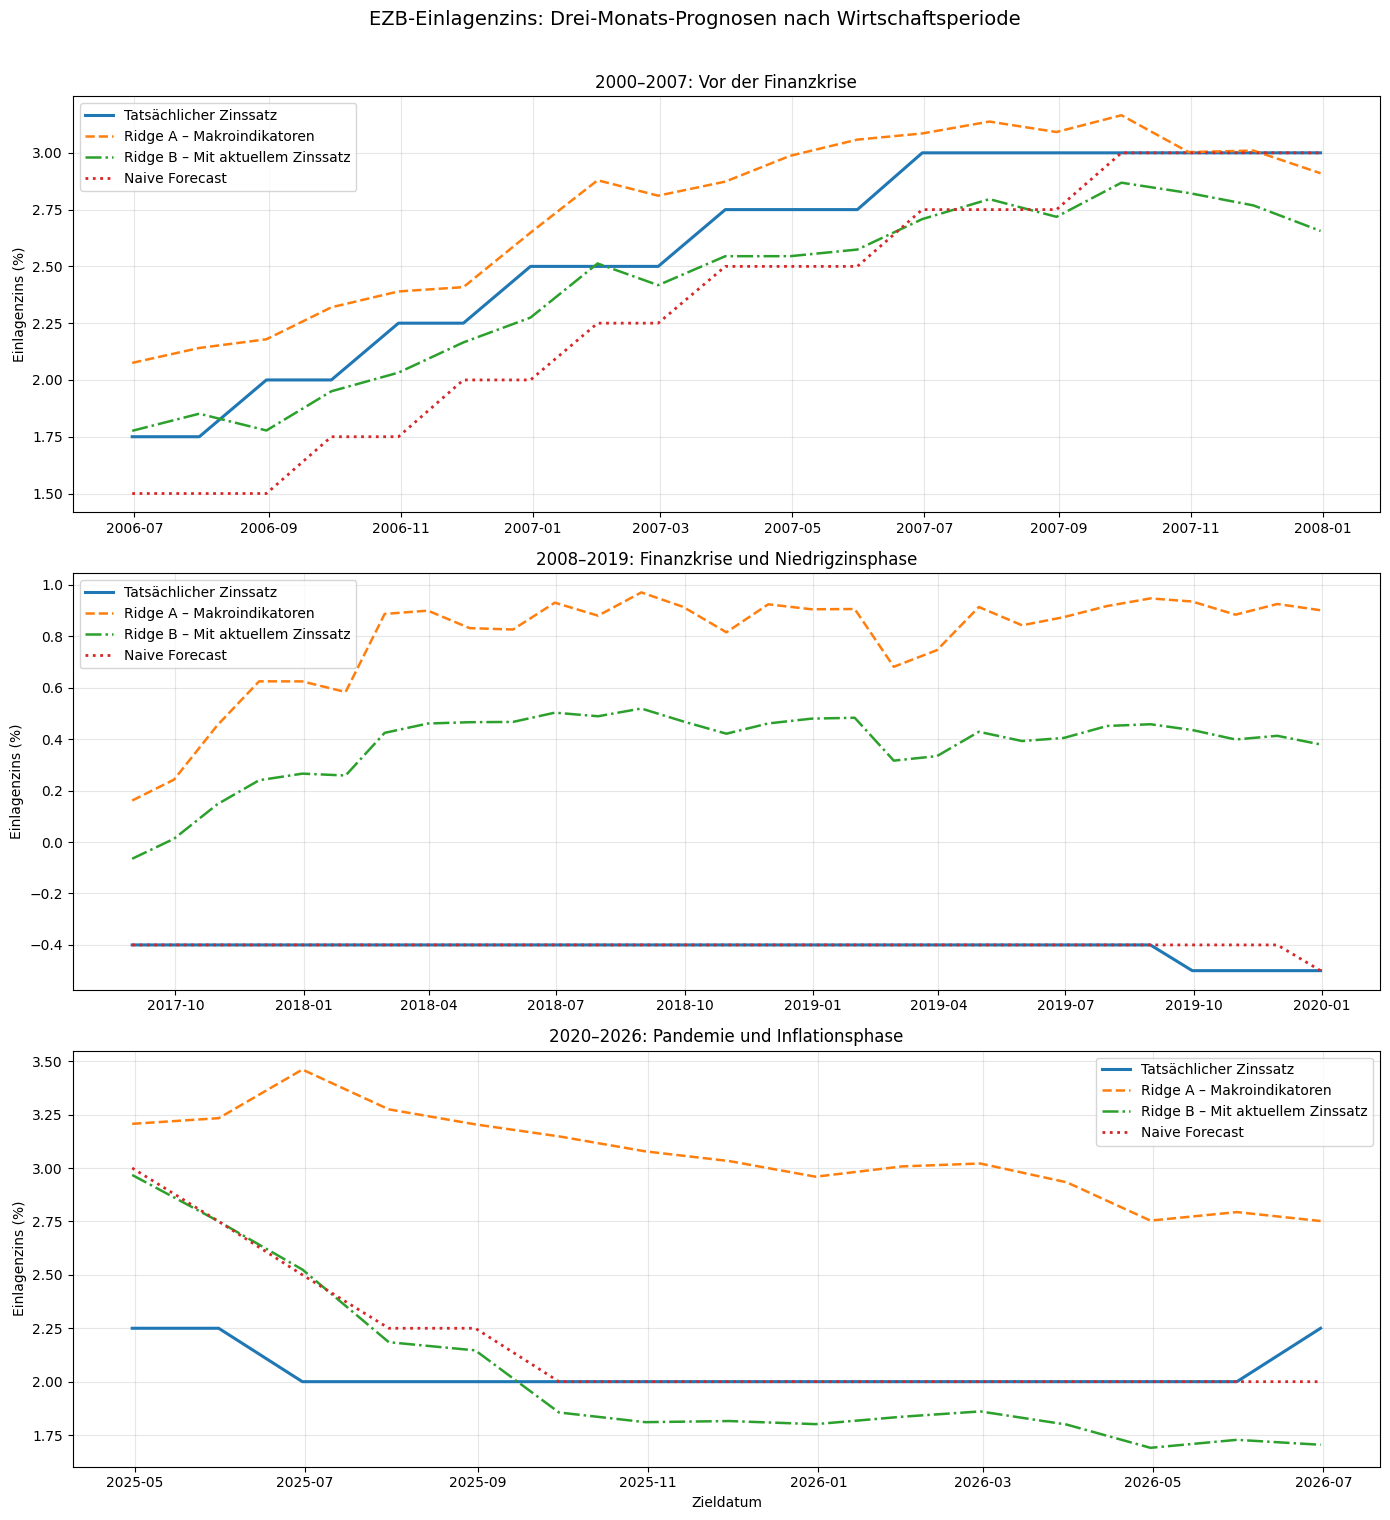

In [ ]:
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("C:/Users/Martin/Desktop/Github/ecb-deposit-rate-forecasting/data/macro_data.csv")
OUTPUT_DIR = Path("C:/Users/Martin/Desktop/Github/ecb-deposit-rate-forecasting")
IMAGE_DIR = OUTPUT_DIR / "images"

IMAGE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)

target = "ECB_Deposit_Rate"

# Ridge A: macroeconomic indicators only
features_a = [
    "Inflation_HICP",
    "Core_Inflation",
    "Unemployment",
    "Industrial",
    "Brent_Oil_Price",
    "EUR_USD",
    "Economic_Sentiment",
]

# Ridge B: current interest rate + macroeconomic indicators
features_b = [target] + features_a

# Economic periods
periods = {
    "2000–2007: Vor der Finanzkrise":
        ("2000-01-01", "2008-01-01"),

    "2008–2019: Finanzkrise und Niedrigzinsphase":
        ("2008-01-01", "2020-01-01"),

    "2020–2026: Pandemie und Inflationsphase":
        ("2020-01-01", "2027-01-01"),
}

print(
    f"Dataset: {df['date'].min().date()} to "
    f"{df['date'].max().date()}"
)
print(f"Total observations: {len(df)}")


all_results = []
all_predictions = []

for period_name, (start_date, end_date) in periods.items():

    period_df = df.loc[
        (df["date"] >= start_date)
        & (df["date"] < end_date)
    ].copy()

    period_df["target_3m"] = period_df[target].shift(-3)
    period_df["target_date"] = period_df["date"].shift(-3)

    period_df = period_df.dropna(
        subset=features_b + ["target_3m", "target_date"]
    ).reset_index(drop=True)

    n = len(period_df)
    split_idx = int(n * 0.8)

    if split_idx < 24 or n - split_idx < 6:
        print(f"Skipping {period_name}: not enough observations.")
        continue

    train = period_df.iloc[:split_idx - 3].copy()
    test = period_df.iloc[split_idx:].copy()

    y_train = train["target_3m"]
    y_test = test["target_3m"]

    # Ridge A: 

    model_a = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0)),
    ])

    model_a.fit(train[features_a], y_train)
    pred_a = model_a.predict(test[features_a])

    # Ridge B

    model_b = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0)),
    ])

    model_b.fit(train[features_b], y_train)
    pred_b = model_b.predict(test[features_b])

    # Naive forecast:

    pred_naive = test[target].to_numpy()

    # Store predictions and evaluation metrics

    model_predictions = {
        "Ridge A": pred_a,
        "Ridge B": pred_b,
        "Naive Forecast": pred_naive,
    }

    for model_name, predictions in model_predictions.items():

        all_results.append({
            "Period": period_name,
            "Model": model_name,
            "Train_N": len(train),
            "Test_N": len(test),
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
            "R2": r2_score(y_test, predictions),
        })

    # One common prediction dataset for all models
    period_predictions = pd.DataFrame({
        "Period": period_name,
        "Forecast_Date": test["date"].to_numpy(),
        "Target_Date": test["target_date"].to_numpy(),
        "Actual_Rate": y_test.to_numpy(),
        "Ridge_A": pred_a,
        "Ridge_B": pred_b,
        "Naive_Forecast": pred_naive,
    })

    all_predictions.append(period_predictions)

    print(
        f"{period_name}: "
        f"Train = {len(train)}, Test = {len(test)}"
    )

# results table

results_df = pd.DataFrame(all_results)

print("\nForecast Performance by Economic Period")
print("=" * 90)
print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    OUTPUT_DIR / "period_model_comparison.csv",
    index=False,
)

predictions_df = pd.concat(all_predictions, ignore_index=True)

predictions_df.to_csv(
    OUTPUT_DIR / "period_model_predictions.csv",
    index=False,
)

# graphs 

fig, axes = plt.subplots(3, 1, figsize=(14, 15))

for ax, (period_name, _) in zip(axes, periods.items()):

    plot_df = predictions_df.loc[
        predictions_df["Period"] == period_name
    ].copy()

    if plot_df.empty:
        ax.set_visible(False)
        continue

    dates = plot_df["Target_Date"]

    ax.plot(
        dates,
        plot_df["Actual_Rate"],
        label="Tatsächlicher Zinssatz",
        linewidth=2.2,
    )

    ax.plot(
        dates,
        plot_df["Ridge_A"],
        label="Ridge A – Makroindikatoren",
        linestyle="--",
        linewidth=1.8,
    )

    ax.plot(
        dates,
        plot_df["Ridge_B"],
        label="Ridge B – Mit aktuellem Zinssatz",
        linestyle="-.",
        linewidth=1.8,
    )

    ax.plot(
        dates,
        plot_df["Naive_Forecast"],
        label="Naive Forecast",
        linestyle=":",
        linewidth=2,
    )

    ax.set_title(period_name)
    ax.set_ylabel("Einlagenzins (%)")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Zieldatum")

fig.suptitle(
    "EZB-Einlagenzins: Drei-Monats-Prognosen nach Wirtschaftsperiode",
    fontsize=14,
    y=1.01,
)

plt.tight_layout()

fig.savefig(
    IMAGE_DIR / "period_forecasts_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


Full-period forecast comparison
Training observations: 249
Test observations:     63

Forecast Performance — Full Test Period
         Model  Train_N  Test_N    MAE   RMSE      R2
       Ridge A      249      63 2.0392 2.7519 -1.8114
       Ridge B      249      63 0.4457 0.6116  0.8611
Naive Forecast      249      63 0.3135 0.4990  0.9076


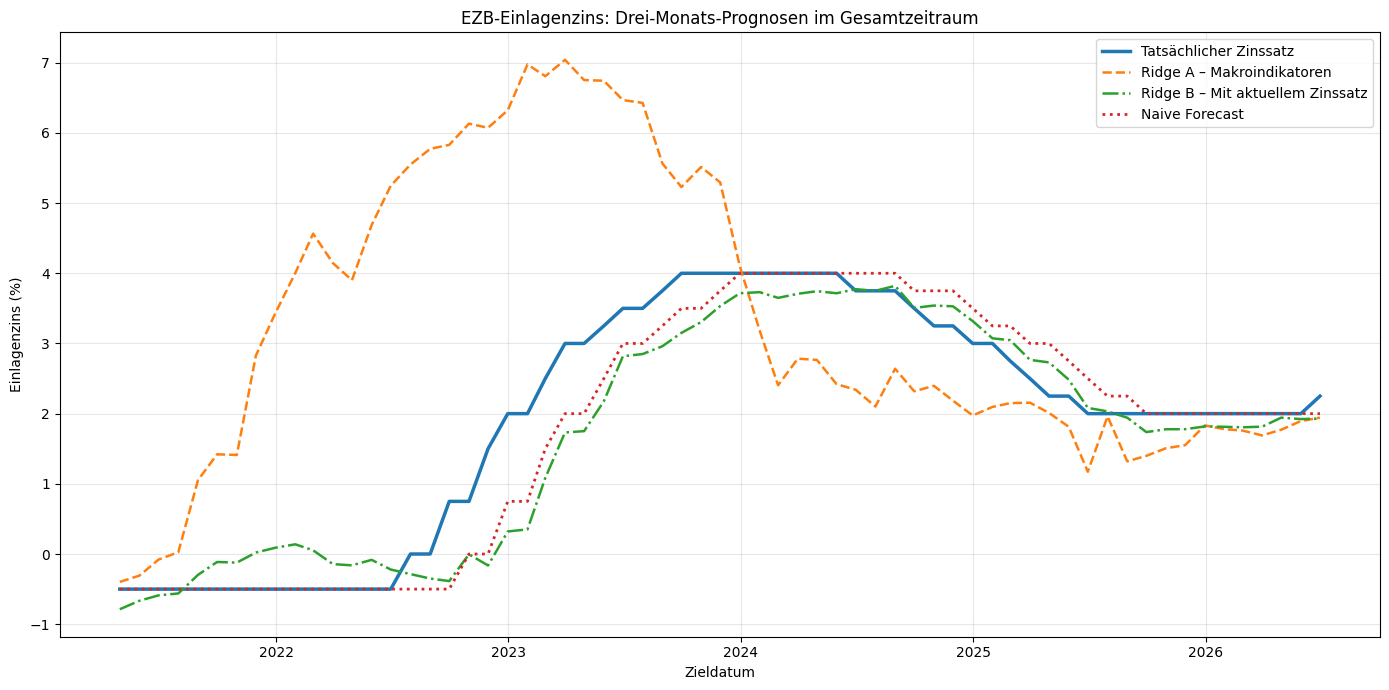


Full-period results and predictions saved.


In [ ]:
# Full-period forecast comparison

features_a = [
    "Inflation_HICP",
    "Core_Inflation",
    "Unemployment",
    "Industrial",
    "Brent_Oil_Price",
    "EUR_USD",
    "Economic_Sentiment",
]

features_b = [target] + features_a
full_data = df.copy()

full_data["target_3m"] = full_data[target].shift(-3)
full_data["target_date"] = full_data["date"].shift(-3)

full_data = full_data.dropna(
    subset=features_b + ["target_3m", "target_date"]
).reset_index(drop=True)


split_idx = int(len(full_data) * 0.8)

train = full_data.iloc[:split_idx - 3].copy()
test = full_data.iloc[split_idx:].copy()

y_train = train["target_3m"]
y_test = test["target_3m"]

print("\nFull-period forecast comparison")
print("=" * 60)
print(f"Training observations: {len(train)}")
print(f"Test observations:     {len(test)}")

# 5.3 Ridge A 

ridge_a = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0)),
])

ridge_a.fit(train[features_a], y_train)
pred_a = ridge_a.predict(test[features_a])

# 5.4 Ridge B 

ridge_b = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0)),
])

ridge_b.fit(train[features_b], y_train)
pred_b = ridge_b.predict(test[features_b])

pred_naive = test[target].to_numpy()

model_predictions = {
    "Ridge A": pred_a,
    "Ridge B": pred_b,
    "Naive Forecast": pred_naive,
}

full_results = []

for model_name, predictions in model_predictions.items():

    full_results.append({
        "Model": model_name,
        "Train_N": len(train),
        "Test_N": len(test),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions),
    })

full_results_df = pd.DataFrame(full_results)

print("\nForecast Performance — Full Test Period")
print("=" * 75)
print(full_results_df.round(4).to_string(index=False))

full_results_df.to_csv(
    OUTPUT_DIR / "full_period_model_comparison.csv",
    index=False,
)

full_predictions_df = pd.DataFrame({
    "Forecast_Date": test["date"].to_numpy(),
    "Target_Date": test["target_date"].to_numpy(),
    "Actual_Rate": y_test.to_numpy(),
    "Ridge_A": pred_a,
    "Ridge_B": pred_b,
    "Naive_Forecast": pred_naive,
})

full_predictions_df.to_csv(
    OUTPUT_DIR / "full_period_model_predictions.csv",
    index=False,
)

# Combined graph

target_dates = test["target_date"]

plt.figure(figsize=(14, 7))

plt.plot(
    target_dates,
    y_test,
    label="Tatsächlicher Zinssatz",
    linewidth=2.5,
)

plt.plot(
    target_dates,
    pred_a,
    label="Ridge A – Makroindikatoren",
    linestyle="--",
    linewidth=1.8,
)

plt.plot(
    target_dates,
    pred_b,
    label="Ridge B – Mit aktuellem Zinssatz",
    linestyle="-.",
    linewidth=1.8,
)

plt.plot(
    target_dates,
    pred_naive,
    label="Naive Forecast",
    linestyle=":",
    linewidth=2,
)

plt.title(
    "EZB-Einlagenzins: Drei-Monats-Prognosen im Gesamtzeitraum"
)
plt.xlabel("Zieldatum")
plt.ylabel("Einlagenzins (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "full_period_forecast_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("\nFull-period results and predictions saved.")


In [ ]:
#  OLS Regression 
import statsmodels.api as sm

features_ols = features_b

regression_data = df[
    ["date", target]
    + features_a
].copy()

regression_data["target_3m"] = regression_data[target].shift(-3)

regression_data = regression_data.dropna(
    subset=features_ols + ["target_3m"]
).copy()

y_ols = regression_data["target_3m"]
X_ols = regression_data[features_ols]

X_ols = sm.add_constant(X_ols)

# Standard OLS R

model_ols = sm.OLS(y_ols, X_ols).fit()

print("\nOLS Regression — 3-Month-Ahead Forecast")
print("=" * 65)
print(model_ols.summary())

#  OLS Regression with HAC / Newey-West Standard Errors

model_hac = sm.OLS(y_ols, X_ols).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 12}
)

print("\nOLS Regression with HAC Standard Errors")
print("=" * 65)
print(model_hac.summary())

regression_comparison = pd.DataFrame({
    "OLS Coefficient": model_ols.params,
    "OLS p-value": model_ols.pvalues,
    "HAC Coefficient": model_hac.params,
    "HAC p-value": model_hac.pvalues,
})

print("\nRegression Results: OLS vs. HAC")
print("=" * 65)
print(regression_comparison.round(4).to_string())

regression_comparison.to_csv(
    OUTPUT_DIR / "ols_hac_regression_comparison.csv"
)

print("\nRegression results saved.")


OLS Regression — 3-Month-Ahead Forecast
                            OLS Regression Results                            
Dep. Variable:              target_3m   R-squared:                       0.963
Model:                            OLS   Adj. R-squared:                  0.962
Method:                 Least Squares   F-statistic:                     982.4
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          3.38e-213
Time:                        04:27:49   Log-Likelihood:                -44.447
No. Observations:                 315   AIC:                             106.9
Df Residuals:                     306   BIC:                             140.7
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------